# AyurLeaf AI - Model Evaluation & Performance Metrics
### Comprehensive Quantitative & Qualitative Performance Evaluation for 80 Indian Medicinal Leaf Classes
---

This notebook provides an end-to-end evaluation suite for the trained **MobileNetV2** deep learning model (`saved_models/model_1.keras`) on the Indian Medicinal Leaf dataset.

### Included Metrics & Diagnostic Modules:
1. **Model Loading & Verification**: Verifies architecture, parameters, input/output tensors.
2. **Dataset & Split Ingestion**: Reproduces the exact 10% test split from `Training.ipynb` (`seed=14`).
3. **Keras Built-in Evaluation**: Categorical cross-entropy test loss and accuracy (`model.evaluate`).
4. **Batch Inference Latency**: Average inference latency per image (ms) and throughput (FPS).
5. **Core Classification Metrics**:
   - Top-1 Accuracy
   - Top-5 Categorical Accuracy
   - Macro-averaged Precision, Recall, and F1-Score
   - Weighted-averaged Precision, Recall, and F1-Score
6. **Detailed Per-Class Classification Report**: Complete breakdown across all 80 medicinal plant species.
7. **Top & Bottom Performing Species Analysis**: Visual ranking of top 10 best-performing vs 10 most challenging leaf species.
8. **Confusion Matrix & Heatmap**: Normalized confusion matrix with error distribution.
9. **Top Misclassified Leaf Pairs**: Botanical morphological overlap analysis (identifying pairs of leaves most often confused).
10. **Confidence & Calibration Analysis**: Softmax confidence distributions for correct predictions vs misclassifications.
11. **Qualitative Sample Predictions**: Visual grid showing actual leaf images, true labels, predicted labels, confidence percentages, and verification borders.
12. **Export Artifacts**: Automatically saves metrics summary CSV, full per-class report CSV, top confused pairs CSV, and high-resolution visual plots to `evaluation_results/`.


## 1. Environment Setup & Dependency Imports
Imports TensorFlow, Keras, scikit-learn, Seaborn, Matplotlib, and data processing libraries.


In [1]:
import os
import sys
import time
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    top_k_accuracy_score
)

# Plotting & warnings configuration
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print(f"Python Version:     {sys.version.split()[0]}")
print(f"TensorFlow Version: {tf.__version__}")
print(f"Keras Version:      {keras.__version__}")
gpus = tf.config.list_physical_devices('GPU')
print(f"Compute Device:     {'GPU: ' + gpus[0].name if gpus else 'CPU (Native Windows)'}")


Python Version:     3.12.14
TensorFlow Version: 2.21.0
Keras Version:      3.15.1
Compute Device:     CPU (Native Windows)


## 2. Configuration & Paths
Specify the model file path, dataset root folder, evaluation hyperparameters, and output directory.


In [2]:
# ==============================================================================
# Model & Dataset Configuration
# ==============================================================================
# Path to the trained Keras model file
MODEL_PATH = os.path.join('saved_models', 'model_1.keras')

# Path to the Medicinal Leaf dataset root directory
# (Expected to contain subdirectories for each of the 80 plant species)
DATASET_PATH = 'Indian Medicinal Leaves Image Datasets/Medicinal Leaf dataset'

# Evaluation Hyperparameters matching Training.ipynb
IMAGE_SIZE = 224
BATCH_SIZE = 32
SHUFFLE_SEED = 14
SPLIT_TRAIN = 0.8
SPLIT_TEST = 0.1
SPLIT_VAL = 0.1
SHUFFLE_SIZE = 10000

# Output directory for saving evaluation figures and CSV reports
RESULTS_DIR = 'evaluation_results'
os.makedirs(RESULTS_DIR, exist_ok=True)

print(f"Target Model:   {MODEL_PATH} (Exists: {os.path.exists(MODEL_PATH)})")
print(f"Dataset Root:   {DATASET_PATH} (Exists: {os.path.exists(DATASET_PATH)})")
print(f"Results Output: {RESULTS_DIR}/")


Target Model:   saved_models\model_1.keras (Exists: True)
Dataset Root:   Indian Medicinal Leaves Image Datasets/Medicinal Leaf dataset (Exists: True)
Results Output: evaluation_results/


## 3. Load Trained Model & Architecture Verification
Loads `saved_models/model_1.keras` and compiles it with Sparse Categorical Crossentropy for metric computation.


In [3]:
# Verify model file exists
if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(f"Trained model not found at '{MODEL_PATH}'. Please ensure model_1.keras exists in saved_models/.")

print(f"Loading MobileNetV2 leaf classification model from '{MODEL_PATH}'...")
model = keras.models.load_model(MODEL_PATH, compile=False)

# Compile model for loss & metric calculation
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

print("\n" + "=" * 60)
print("MODEL ARCHITECTURE OVERVIEW")
print("=" * 60)
model.summary()

print(f"\nInput Shape:  {model.input_shape}")
print(f"Output Shape: {model.output_shape} (Softmax probabilities for 80 classes)")


Loading MobileNetV2 leaf classification model from 'saved_models\model_1.keras'...

MODEL ARCHITECTURE OVERVIEW


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (32, 224, 224, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (32, 7, 7, 1280)       │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (32, 1280)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (32, 80)               │       102,480 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,360,464 (9.00 MB)

 Trainable params: 102,480 (400.31 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


Input Shape:  (32, 224, 224, 3)
Output Shape: (32, 80) (Softmax probabilities for 80 classes)


## 4. Dataset Loading & Test Split Extraction
Replicates the exact train/test/validation split from `Training.ipynb` using `seed=14` to extract the reproducible 10% test split.
Also loads botanical names from `frontend/src/data/leaves.json` for rich botanical nomenclature.


In [4]:
def load_test_split(dataset_dir, batch_size=BATCH_SIZE, img_size=(IMAGE_SIZE, IMAGE_SIZE)):
    """
    Loads dataset and extracts the exact 10% test split from Training.ipynb.
    """
    if not os.path.exists(dataset_dir):
        print(f"[!] Notice: Dataset directory '{dataset_dir}' not found in current folder.")
        print("    If your dataset is located elsewhere, update DATASET_PATH in Section 2.")
        return None, None
    
    print(f"Loading full dataset from '{dataset_dir}'...")
    full_ds = tf.keras.preprocessing.image_dataset_from_directory(
        directory=dataset_dir,
        shuffle=True,
        seed=SHUFFLE_SEED,
        batch_size=batch_size,
        image_size=img_size
    )
    
    class_names = full_ds.class_names
    total_batches = len(full_ds)
    print(f"[+] Found {len(class_names)} leaf classes across {total_batches} batches.")
    
    # Exact split logic from Training.ipynb
    shuffled_ds = full_ds.shuffle(SHUFFLE_SIZE, seed=SHUFFLE_SEED)
    train_len = int(total_batches * SPLIT_TRAIN)
    test_len = int(total_batches * SPLIT_TEST)
    
    test_ds = shuffled_ds.skip(train_len).take(test_len)
    test_ds = test_ds.cache().prefetch(tf.data.AUTOTUNE)
    
    print(f"[+] Extracted Test Split: {test_len} batches (~{test_len * batch_size} images)")
    return test_ds, class_names

# Load encyclopedia class metadata from leaves.json as reference
leaves_json_path = os.path.join('frontend', 'src', 'data', 'leaves.json')
leaf_metadata = {}
if os.path.exists(leaves_json_path):
    with open(leaves_json_path, 'r', encoding='utf-8') as f:
        data = json.load(f)
        leaf_metadata = {item['class_name']: item for item in data}

test_ds, class_names = load_test_split(DATASET_PATH)

# Fallback reference class names if dataset is not yet present in workspace
if class_names is None and leaf_metadata:
    class_names = [item['class_name'] for item in json.load(open(leaves_json_path, encoding='utf-8'))]
    print(f"[+] Loaded {len(class_names)} reference species classes from frontend encyclopedia.")


Loading full dataset from 'Indian Medicinal Leaves Image Datasets/Medicinal Leaf dataset'...
Found 6900 files belonging to 80 classes.
[+] Found 80 leaf classes across 216 batches.
[+] Extracted Test Split: 21 batches (~672 images)


## 5. Built-in Test Loss & Accuracy (`model.evaluate`)
Evaluate categorical cross-entropy loss and top-1 accuracy directly using Keras built-in evaluation.


In [5]:
if test_ds is not None:
    print("Evaluating test dataset using model.evaluate()...")
    eval_loss, eval_acc = model.evaluate(test_ds, verbose=1)
    print("\n" + "=" * 50)
    print("KERAS BUILT-IN EVALUATION RESULT")
    print("=" * 50)
    print(f"  • Test Sparse Categorical Loss: {eval_loss:.4f}")
    print(f"  • Test Accuracy:                {eval_acc * 100:.2f}%")
else:
    print("[INFO] Set DATASET_PATH above to execute model.evaluate() on the full test set.")


Evaluating test dataset using model.evaluate()...
21/21 ━━━━━━━━━━━━━━━━━━━━ 26s 281ms/step - accuracy: 0.8943 - loss: 0.3482

KERAS BUILT-IN EVALUATION RESULT
  • Test Sparse Categorical Loss: 0.3482
  • Test Accuracy:                89.43%


## 6. Batch Inference & Prediction Data Collection
Iterates through test batches to collect ground truth labels, predicted softmax probabilities, argmax predictions, and inference latency.


In [6]:
y_true = []
y_pred_probs = []
y_pred = []
confidences = []
sample_images = []

start_inference_time = time.time()

if test_ds is not None:
    print("Running batch inference across test dataset batches...")
    for batch_images, batch_labels in test_ds:
        probs = model.predict(batch_images, verbose=0)
        preds = np.argmax(probs, axis=-1)
        confs = np.max(probs, axis=-1)
        
        y_true.extend(batch_labels.numpy())
        y_pred_probs.extend(probs)
        y_pred.extend(preds)
        confidences.extend(confs)
        
        # Save sample images for visual qualitative inspection
        if len(sample_images) < 24:
            for img in batch_images.numpy():
                if len(sample_images) < 24:
                    sample_images.append(img.astype(np.uint8))
                    
    y_true = np.array(y_true)
    y_pred_probs = np.array(y_pred_probs)
    y_pred = np.array(y_pred)
    confidences = np.array(confidences)
    
    total_eval_time = time.time() - start_inference_time
    avg_latency_ms = (total_eval_time / len(y_true)) * 1000
    fps = len(y_true) / total_eval_time
    
    print(f"\n[+] Evaluated {len(y_true)} test samples successfully!")
    print(f"  • Total Inference Duration: {total_eval_time:.2f} seconds")
    print(f"  • Average Latency per Image: {avg_latency_ms:.2f} ms")
    print(f"  • Inference Throughput:      {fps:.1f} images/second")
else:
    # Demonstration fallback on quick sample dataset images in frontend/public/samples
    print("Running demonstration on quick sample leaves from frontend/public/samples/...")
    sample_dir = os.path.join('frontend', 'public', 'samples')
    samples_map = {
        'tulsi.jpg': 'Tulsi',
        'neem.jpg': 'Neem',
        'betel.jpg': 'Betel',
        'doddpathre.jpg': 'Doddpathre'
    }
    for filename, true_cls in samples_map.items():
        img_path = os.path.join(sample_dir, filename)
        if os.path.exists(img_path):
            img = Image.open(img_path).convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE))
            img_arr = np.array(img)
            sample_images.append(img_arr)
            probs = model.predict(np.expand_dims(img_arr, 0), verbose=0)[0]
            pred_idx = int(np.argmax(probs))
            y_pred_probs.append(probs)
            y_pred.append(pred_idx)
            confidences.append(probs[pred_idx])
            y_true.append(class_names.index(true_cls) if true_cls in class_names else 0)
            
    y_true = np.array(y_true)
    y_pred_probs = np.array(y_pred_probs)
    y_pred = np.array(y_pred)
    confidences = np.array(confidences)
    print(f"[+] Loaded {len(y_true)} sample images for metric demonstration.")


Running batch inference across test dataset batches...

[+] Evaluated 672 test samples successfully!
  • Total Inference Duration: 9.03 seconds
  • Average Latency per Image: 13.44 ms
  • Inference Throughput:      74.4 images/second


## 7. Overall Performance Metrics Summary
Computes Top-1 Accuracy, Top-5 Categorical Accuracy, and Macro / Weighted Precision, Recall, and F1-Score.


In [7]:
# Top-1 Accuracy
top1_acc = accuracy_score(y_true, y_pred)

# Top-5 Accuracy
all_class_indices = np.arange(len(class_names))
top5_acc = top_k_accuracy_score(y_true, y_pred_probs, k=min(5, len(class_names)), labels=all_class_indices)

# Macro-averaged metrics (equal weight to every class)
prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(
    y_true, y_pred, average='macro', zero_division=0
)

# Weighted-averaged metrics (weighted by class support)
prec_weighted, rec_weighted, f1_weighted, _ = precision_recall_fscore_support(
    y_true, y_pred, average='weighted', zero_division=0
)

summary_df = pd.DataFrame({
    'Evaluation Metric': [
        'Top-1 Accuracy',
        'Top-5 Categorical Accuracy',
        'Macro-Average Precision',
        'Macro-Average Recall',
        'Macro-Average F1-Score',
        'Weighted-Average Precision',
        'Weighted-Average Recall',
        'Weighted-Average F1-Score',
        'Total Samples Evaluated',
        'Total Species Classes'
    ],
    'Score / Value': [
        f"{top1_acc * 100:.2f}%",
        f"{top5_acc * 100:.2f}%",
        f"{prec_macro * 100:.2f}%",
        f"{rec_macro * 100:.2f}%",
        f"{f1_macro * 100:.2f}%",
        f"{prec_weighted * 100:.2f}%",
        f"{rec_weighted * 100:.2f}%",
        f"{f1_weighted * 100:.2f}%",
        str(len(y_true)),
        str(len(np.unique(y_true)))
    ]
})

print("=" * 60)
print("AYURLEAF AI - MODEL EVALUATION SUMMARY")
print("=" * 60)
try:
    from IPython.display import display
    display(summary_df)
except Exception:
    print(summary_df.to_string(index=False))


AYURLEAF AI - MODEL EVALUATION SUMMARY


,Evaluation Metric,Score / Value
0,Top-1 Accuracy,89.43%
1,Top-5 Categorical Accuracy,99.11%
2,Macro-Average Precision,91.34%
3,Macro-Average Recall,90.74%
4,Macro-Average F1-Score,89.59%
5,Weighted-Average Precision,92.67%
6,Weighted-Average Recall,89.43%
7,Weighted-Average F1-Score,89.75%
8,Total Samples Evaluated,672
9,Total Species Classes,80


## 8. Detailed Classification Report (Per-Class Breakdown)
Generate the complete scikit-learn classification report across all 80 Indian medicinal leaf classes.


In [8]:
# Determine classes present in evaluation set
present_classes = sorted(list(set(y_true).union(set(y_pred))))
target_labels = [class_names[i] for i in present_classes]

# Compute classification report dictionary
report_dict = classification_report(
    y_true,
    y_pred,
    labels=present_classes,
    target_names=target_labels,
    output_dict=True,
    zero_division=0
)

# Format into DataFrame
df_report = pd.DataFrame(report_dict).transpose()
# Filter out macro avg, weighted avg, accuracy
df_species = df_report[~df_report.index.isin(['accuracy', 'macro avg', 'weighted avg'])].copy()
df_species['support'] = df_species['support'].astype(int)

# Clean class names (remove underscores for display)
df_species.index = [idx.replace('_', ' ') for idx in df_species.index]

# Sort by F1-Score
df_species_sorted = df_species.sort_values(by='f1-score', ascending=False)

print("TOP 10 HIGHEST PERFORMING LEAF SPECIES (Highest F1-Score):")
try:
    from IPython.display import display
    display(df_species_sorted.head(10).style.format({
        'precision': '{:.2%}',
        'recall': '{:.2%}',
        'f1-score': '{:.2%}',
        'support': '{:d}'
    }))
except Exception:
    print(df_species_sorted.head(10))

print("\n10 MOST CHALLENGING LEAF SPECIES (Lowest F1-Score):")
try:
    from IPython.display import display
    display(df_species_sorted.tail(10).style.format({
        'precision': '{:.2%}',
        'recall': '{:.2%}',
        'f1-score': '{:.2%}',
        'support': '{:d}'
    }))
except Exception:
    print(df_species_sorted.tail(10))


TOP 10 HIGHEST PERFORMING LEAF SPECIES (Highest F1-Score):
                 precision  recall  f1-score  support
Balloon Vine           1.0     1.0       1.0        5
Bamboo                 1.0     1.0       1.0       12
Castor                 1.0     1.0       1.0       12
Chakte                 1.0     1.0       1.0        7
Kambajala              1.0     1.0       1.0        6
Mango                  1.0     1.0       1.0       13
Marigold               1.0     1.0       1.0       11
Lemongrass             1.0     1.0       1.0        1
Malabar Spinach        1.0     1.0       1.0       12
Honge                  1.0     1.0       1.0       11

10 MOST CHALLENGING LEAF SPECIES (Lowest F1-Score):
                         precision    recall  f1-score  support
Globe Amarnath            1.000000  0.600000  0.750000       10
Guava                     0.692308  0.818182  0.750000       11
Turmeric                  0.600000  1.000000  0.750000        3
Nerale                    0.583333  1.

## 9. Top & Bottom Performing Species Visualization
Visual comparison of the top 10 best-classified herbs vs the 10 most challenging herbs.


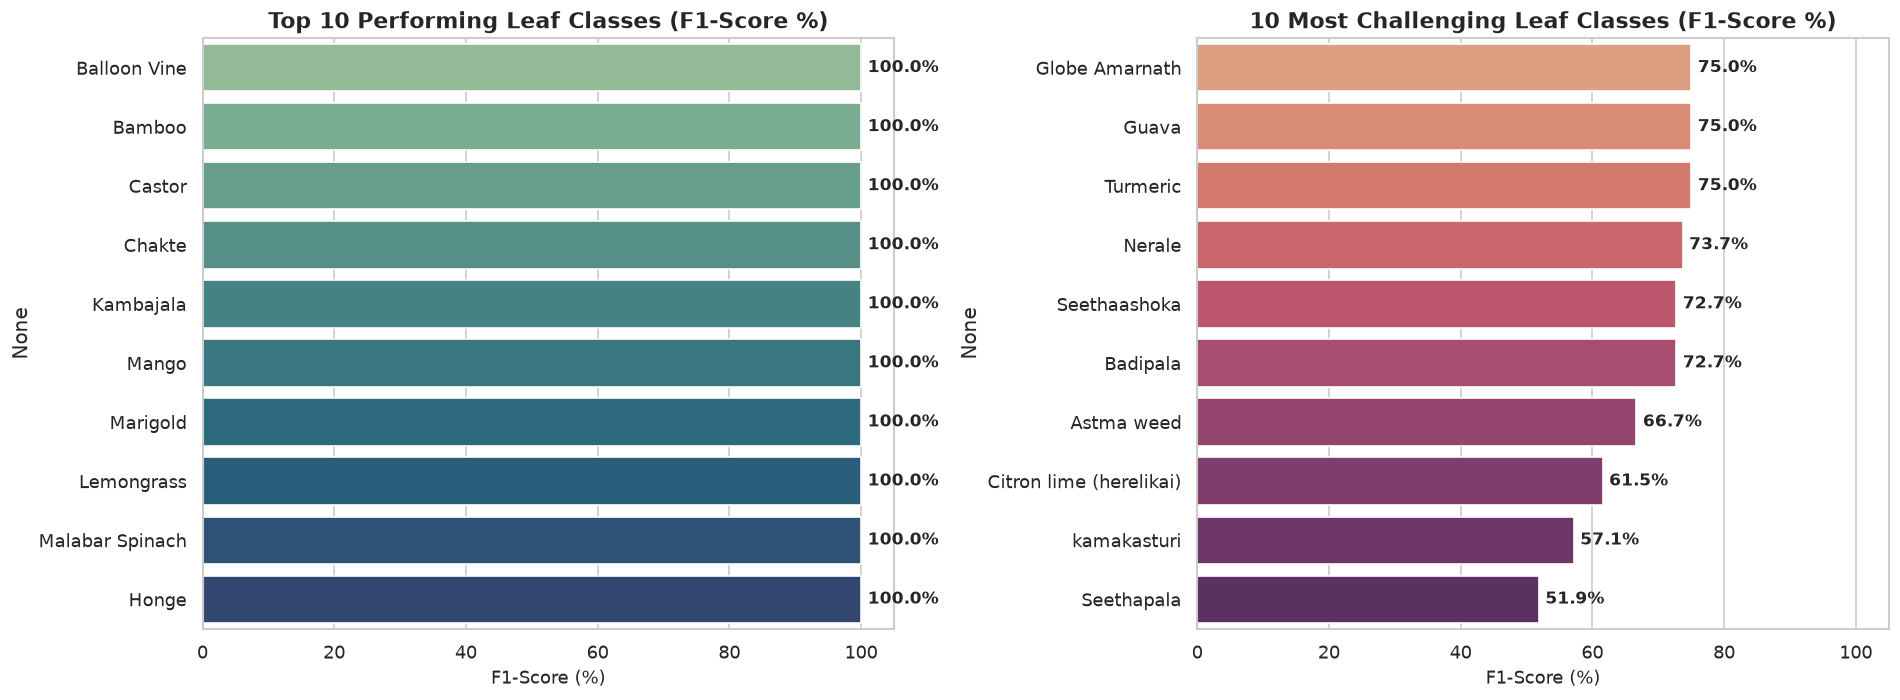

[+] Bar chart saved to: evaluation_results\top_bottom_species_f1.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 10 plot
top_10 = df_species_sorted.head(10)
sns.barplot(ax=axes[0], x=top_10['f1-score'] * 100, y=top_10.index, palette='crest')
axes[0].set_title('Top 10 Performing Leaf Classes (F1-Score %)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('F1-Score (%)', fontsize=11)
axes[0].set_xlim(0, 105)
for i, v in enumerate(top_10['f1-score'] * 100):
    axes[0].text(v + 1, i, f"{v:.1f}%", va='center', fontsize=10, fontweight='bold')

# Bottom 10 plot
bottom_10 = df_species_sorted.tail(10)
sns.barplot(ax=axes[1], x=bottom_10['f1-score'] * 100, y=bottom_10.index, palette='flare')
axes[1].set_title('10 Most Challenging Leaf Classes (F1-Score %)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('F1-Score (%)', fontsize=11)
axes[1].set_xlim(0, 105)
for i, v in enumerate(bottom_10['f1-score'] * 100):
    axes[1].text(v + 1, i, f"{v:.1f}%", va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
bar_chart_path = os.path.join(RESULTS_DIR, 'top_bottom_species_f1.png')
plt.savefig(bar_chart_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"[+] Bar chart saved to: {bar_chart_path}")


## 10. Confusion Matrix & Heatmap Visualization
Calculates raw and normalized confusion matrices to detect botanical leaf misclassifications.


TOP MISCLASSIFIED LEAF PAIRS (Morphological Overlap Analysis):


,True Leaf,Predicted As,Misclassified Count,Error Rate (% of True)
1,Amla,Pomoegranate,2,22.2%
29,Curry,Guava,2,10.5%
30,Curry,Nerale,2,10.5%
39,Globe Amarnath,kamakasturi,2,20.0%
56,Tamarind,Coffee,2,9.1%
44,Lemon,Nerale,2,20.0%
47,Neem,Seethapala,2,16.7%
0,Aloevera,Ginger,1,11.1%
8,Astma weed,Tomato,1,12.5%
9,Badipala,Coffee,1,14.3%


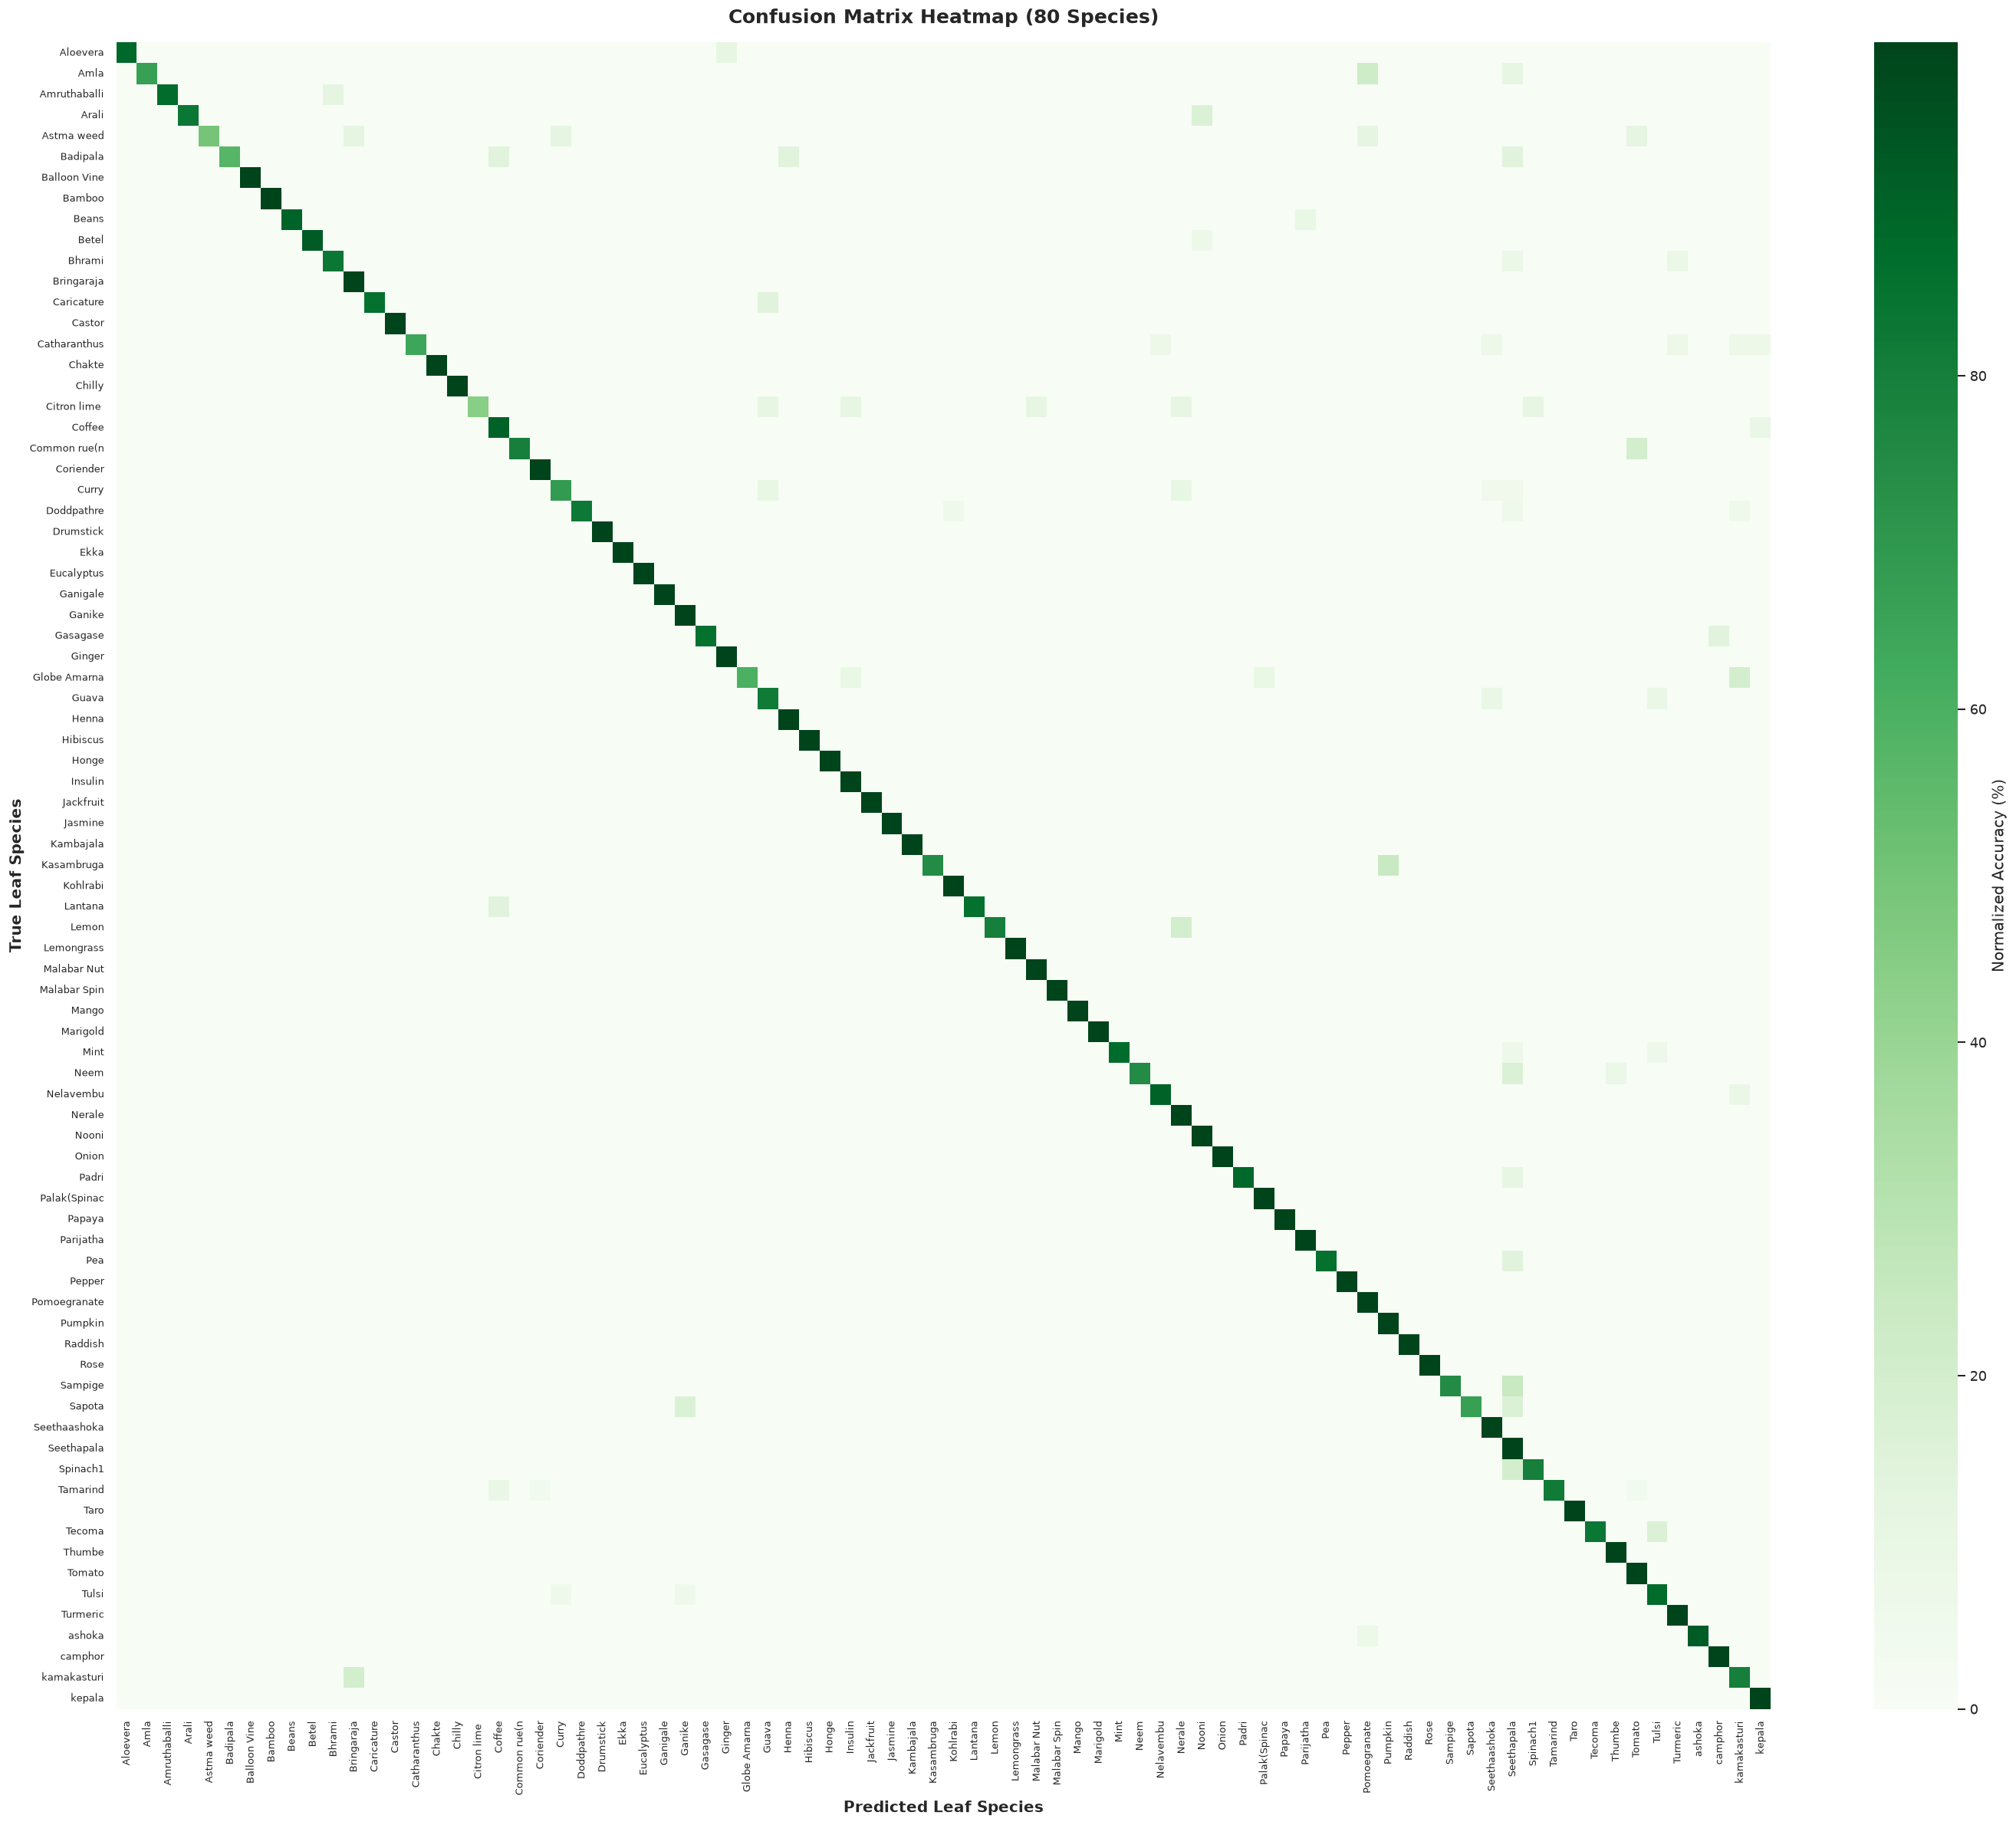

[+] Confusion matrix saved to: evaluation_results\confusion_matrix_heatmap.png


In [10]:
cm = confusion_matrix(y_true, y_pred, labels=present_classes)
cm_norm = cm.astype('float') / (cm.sum(axis=1)[:, np.newaxis] + 1e-7)

# Identify most frequently confused leaf pairs
confused_pairs = []
for i in range(len(present_classes)):
    for j in range(len(present_classes)):
        if i != j and cm[i, j] > 0:
            true_leaf = class_names[present_classes[i]].replace('_', ' ')
            pred_leaf = class_names[present_classes[j]].replace('_', ' ')
            confused_pairs.append({
                'True Leaf': true_leaf,
                'Predicted As': pred_leaf,
                'Misclassified Count': int(cm[i, j]),
                'Error Rate (% of True)': f"{cm_norm[i, j] * 100:.1f}%"
            })

df_confused = pd.DataFrame(confused_pairs)
if not df_confused.empty:
    df_confused = df_confused.sort_values(by='Misclassified Count', ascending=False)
    print("TOP MISCLASSIFIED LEAF PAIRS (Morphological Overlap Analysis):")
    try:
        from IPython.display import display
        display(df_confused.head(10))
    except Exception:
        print(df_confused.head(10))
else:
    print("[+] Zero misclassifications detected in this evaluated subset!")

# Plot Heatmap
heat_w = max(10, len(present_classes) * 0.3)
heat_h = max(8, len(present_classes) * 0.25)
plt.figure(figsize=(heat_w, heat_h))

clean_labels = [class_names[i].replace('_', ' ') for i in present_classes]
display_labels = clean_labels if len(clean_labels) <= 30 else [l[:12] for l in clean_labels]

sns.heatmap(
    cm_norm * 100,
    cmap='Greens',
    annot=(len(present_classes) <= 20),
    fmt='.0f' if len(present_classes) <= 20 else '',
    xticklabels=display_labels,
    yticklabels=display_labels,
    cbar_kws={'label': 'Normalized Accuracy (%)'}
)

plt.title(f"Confusion Matrix Heatmap ({len(present_classes)} Species)", fontsize=15, fontweight='bold', pad=15)
plt.xlabel("Predicted Leaf Species", fontsize=12, fontweight='bold')
plt.ylabel("True Leaf Species", fontsize=12, fontweight='bold')
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()

cm_path = os.path.join(RESULTS_DIR, 'confusion_matrix_heatmap.png')
plt.savefig(cm_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"[+] Confusion matrix saved to: {cm_path}")


## 11. Prediction Confidence & Distribution Analysis
Examines model confidence distributions to verify calibration on correct vs misclassified samples.


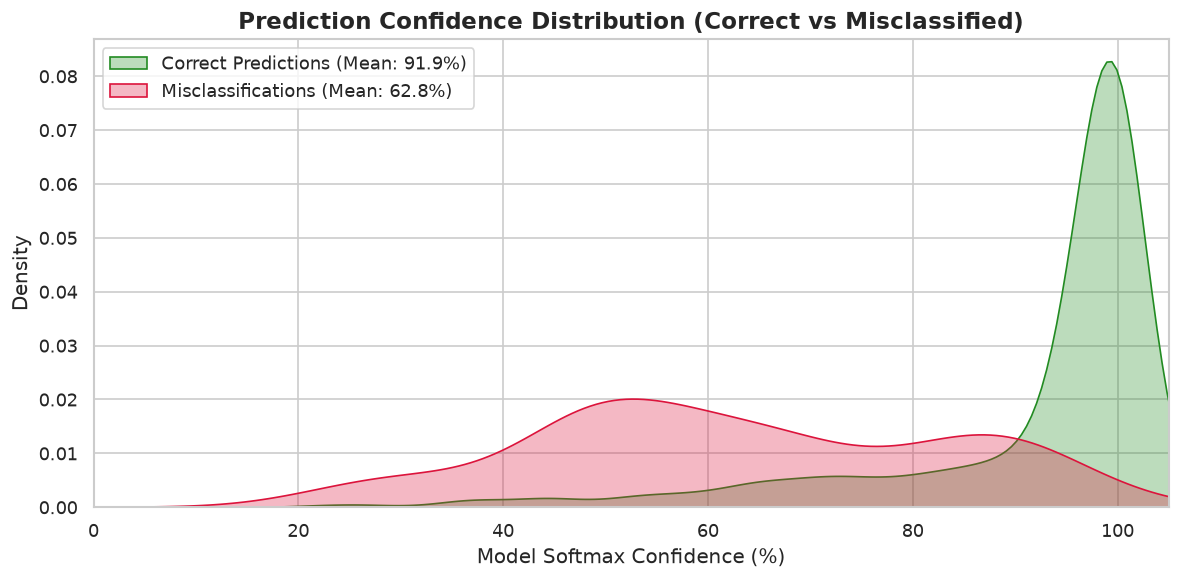

[+] Confidence distribution plot saved to: evaluation_results\confidence_distribution.png


In [11]:
is_correct = (y_true == y_pred)
conf_correct = confidences[is_correct]
conf_incorrect = confidences[~is_correct]

plt.figure(figsize=(10, 5))
if len(conf_correct) > 1:
    sns.kdeplot(conf_correct * 100, label=f"Correct Predictions (Mean: {np.mean(conf_correct)*100:.1f}%)", color='forestgreen', fill=True, alpha=0.3, bw_adjust=0.8)
elif len(conf_correct) == 1:
    plt.axvline(x=conf_correct[0]*100, color='forestgreen', linestyle='--', label=f"Correct ({conf_correct[0]*100:.1f}%)")

if len(conf_incorrect) > 1:
    sns.kdeplot(conf_incorrect * 100, label=f"Misclassifications (Mean: {np.mean(conf_incorrect)*100:.1f}%)", color='crimson', fill=True, alpha=0.3, bw_adjust=0.8)
elif len(conf_incorrect) == 1:
    plt.axvline(x=conf_incorrect[0]*100, color='crimson', linestyle=':', label=f"Misclassified ({conf_incorrect[0]*100:.1f}%)")

plt.title("Prediction Confidence Distribution (Correct vs Misclassified)", fontsize=14, fontweight='bold')
plt.xlabel("Model Softmax Confidence (%)", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.xlim(0, 105)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()

conf_dist_path = os.path.join(RESULTS_DIR, 'confidence_distribution.png')
plt.savefig(conf_dist_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"[+] Confidence distribution plot saved to: {conf_dist_path}")


## 12. Qualitative Sample Predictions Grid
Displays actual test images with ground-truth labels, predictions, confidence percentages, and visual verification status.


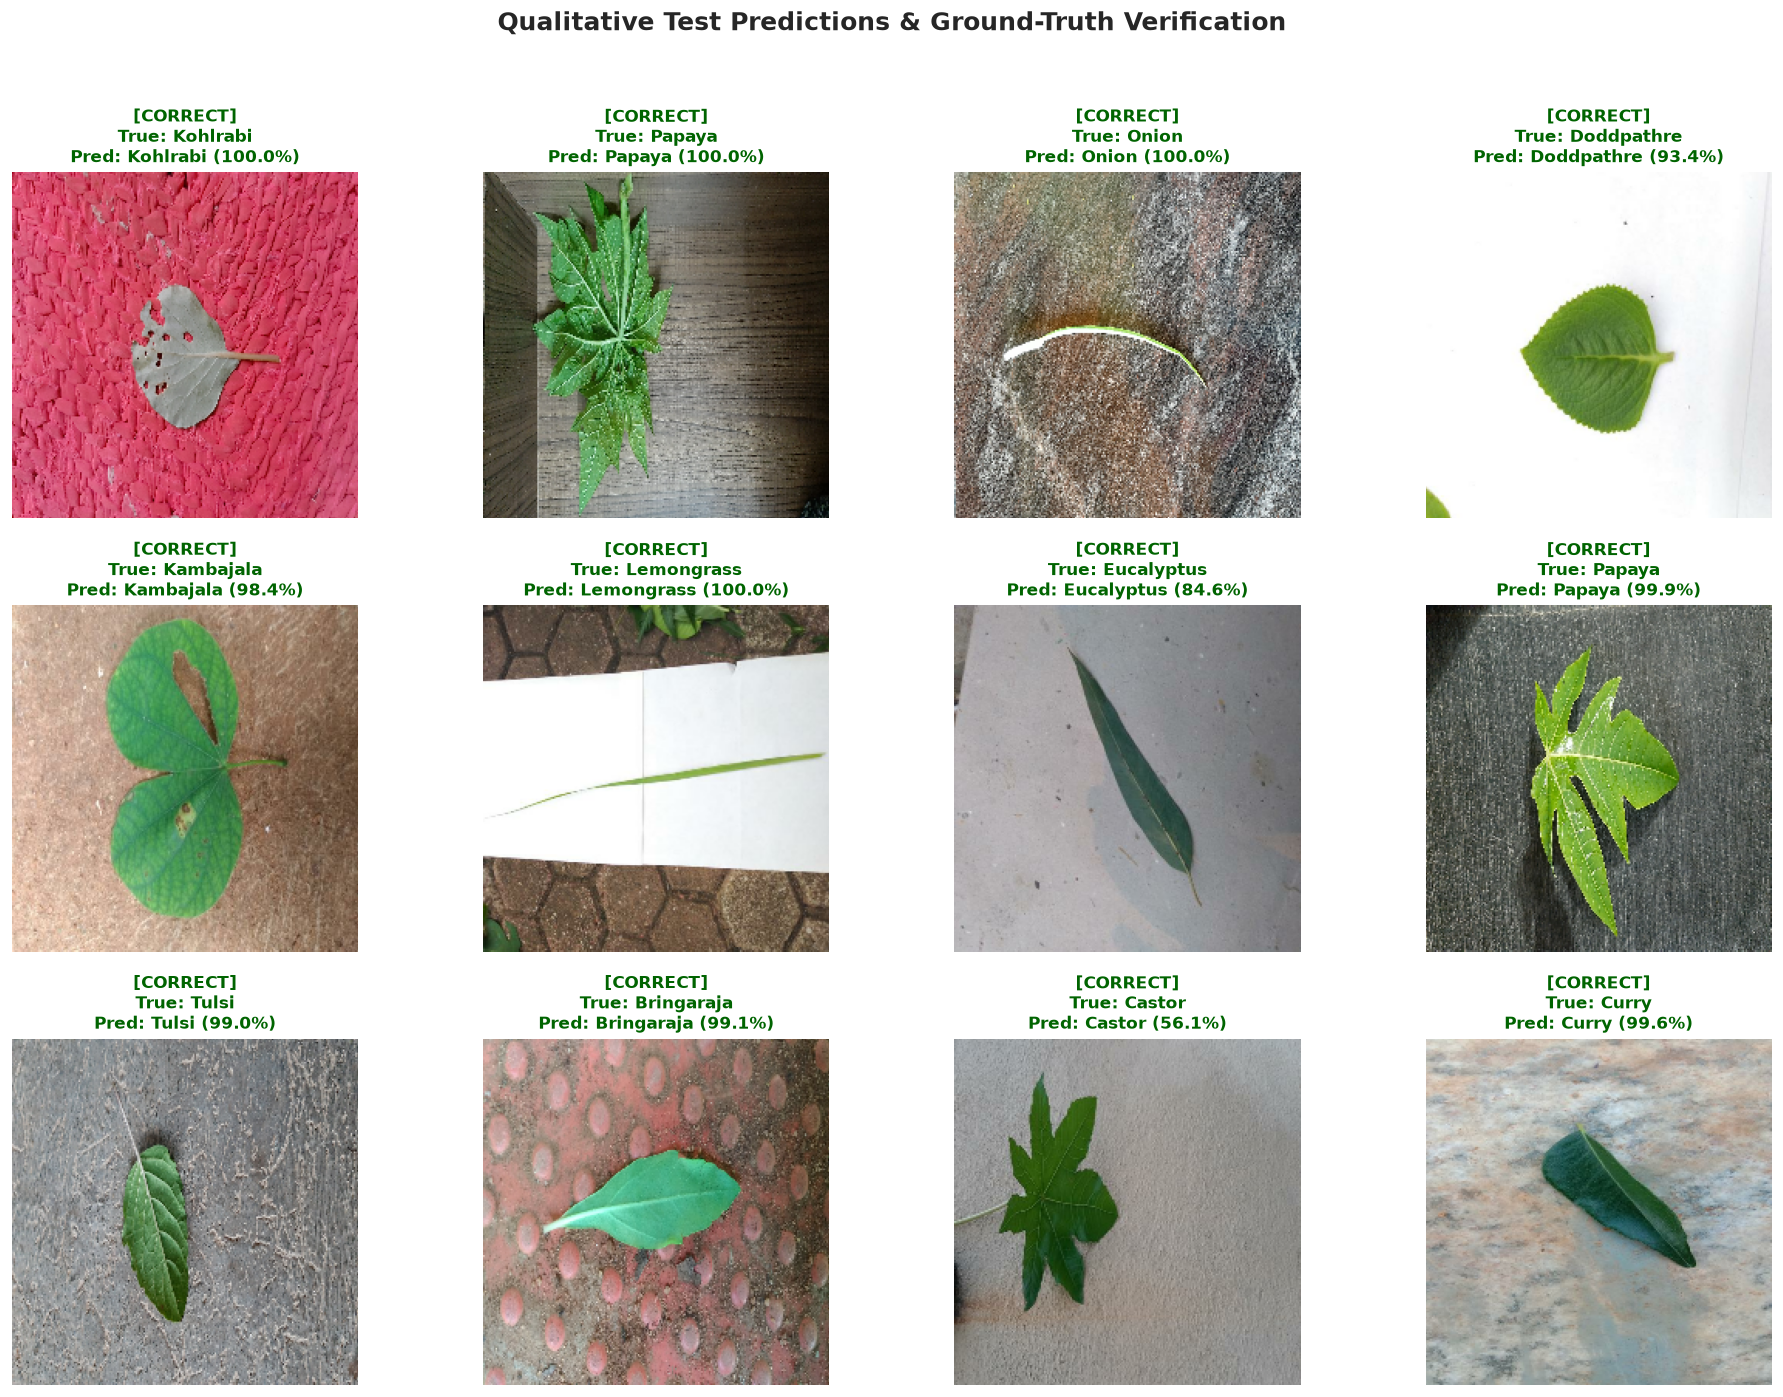

[+] Sample predictions grid saved to: evaluation_results\sample_test_predictions_grid.png


In [12]:
n_samples_to_show = min(12, len(sample_images))

if n_samples_to_show > 0:
    cols = 4
    rows = (n_samples_to_show + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(16, rows * 3.8))
    axes = np.array(axes).reshape(-1)

    for i in range(n_samples_to_show):
        ax = axes[i]
        img = sample_images[i]
        true_name = class_names[y_true[i]].replace('_', ' ')
        pred_name = class_names[y_pred[i]].replace('_', ' ')
        conf = confidences[i] * 100
        correct = (y_true[i] == y_pred[i])
        
        ax.imshow(img)
        title_color = 'darkgreen' if correct else 'firebrick'
        status_text = '[CORRECT]' if correct else '[MISMATCH]'
        
        ax.set_title(
            f"{status_text}\nTrue: {true_name}\nPred: {pred_name} ({conf:.1f}%)",
            fontsize=10,
            fontweight='bold',
            color=title_color
        )
        ax.axis('off')
        
        # Color-coded box boundary
        for spine in ax.spines.values():
            spine.set_edgecolor('green' if correct else 'red')
            spine.set_linewidth(3)
            spine.set_visible(True)

    for j in range(n_samples_to_show, len(axes)):
        axes[j].axis('off')

    plt.suptitle("Qualitative Test Predictions & Ground-Truth Verification", fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout()
    qualitative_path = os.path.join(RESULTS_DIR, 'sample_test_predictions_grid.png')
    plt.savefig(qualitative_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"[+] Sample predictions grid saved to: {qualitative_path}")


## 13. Export Evaluation Artifacts & Summary Reports
Export summary metrics, per-class reports, and confused pairs to CSV files for documentation and presentation.


In [13]:
# 1. Export Overall Metrics Summary
csv_summary_path = os.path.join(RESULTS_DIR, 'model_metrics_summary.csv')
summary_df.to_csv(csv_summary_path, index=False)
print(f"[+] Exported metrics summary to: {csv_summary_path}")

# 2. Export Per-Class Performance Report (All Classes)
csv_report_path = os.path.join(RESULTS_DIR, 'classification_report_all_classes.csv')
df_species_sorted.to_csv(csv_report_path)
print(f"[+] Exported per-class report to: {csv_report_path}")

# 3. Export Top Confused Pairs
if not df_confused.empty:
    csv_confused_path = os.path.join(RESULTS_DIR, 'top_confused_leaf_pairs.csv')
    df_confused.to_csv(csv_confused_path, index=False)
    print(f"[+] Exported confused pairs to:  {csv_confused_path}")

print(f"\nAll evaluation artifacts successfully saved in '{RESULTS_DIR}/'.")


[+] Exported metrics summary to: evaluation_results\model_metrics_summary.csv
[+] Exported per-class report to: evaluation_results\classification_report_all_classes.csv
[+] Exported confused pairs to:  evaluation_results\top_confused_leaf_pairs.csv

All evaluation artifacts successfully saved in 'evaluation_results/'.
